> Runs on its own: all the code is inside this notebook (copied from `src/`), so you can open just this file, e.g. in Colab, or run it from the cloned repo (Anaconda Jupyter on Windows/Linux/macOS, or Colab after cloning https://github.com/Rishabh-bgp/iot-n8n-wind-turbine-predictive-maintenance). Install dependencies once with `%pip install -r requirements.txt` (or `%pip install -r ../requirements.txt` from `notebooks/`). The data cell finds the committed synthetic CSV, downloads it from GitHub, or regenerates it.

# Walkthrough: forecasting models + health index behind the n8n workflow
Simplified version of `src/train_eval.py`. Reference implementation of my paper, rebuilt on synthetic data; numbers will differ from the published ones.

## Please read first: what these numbers mean
This notebook is a **short teaching demo on synthetic (computer-generated) data**. It is **not** a reproduction of the paper's results, and the numbers below should not be compared with the paper's tables.

- The data in `data/` is made up by a seeded generator. The real SCADA data is confidential and is not in this repository.
- The model trains for only a few minutes on a CPU, so it is much smaller and less tuned than in the paper.
- The model predicts the **change from the last reading** (the *persistence* forecast, "next hour = this hour") and adds it back. A fair test of any wind forecaster is whether it beats persistence, so both are printed side by side, with the real numbers, whatever they are.

In [1]:
# install anything missing (Colab already has most of these)
import importlib.util, subprocess, sys
missing = [m for m in ['numpy','pandas','torch','matplotlib'] if importlib.util.find_spec(m) is None]
if missing: subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q'] + [{'sklearn': 'scikit-learn'}.get(m, m) for m in missing])
import os, urllib.request
from pathlib import Path
os.environ.setdefault('OMP_NUM_THREADS', '2')
REPO = 'iot-n8n-wind-turbine-predictive-maintenance'

def find_csv(name):
    """../data/synthetic -> data/synthetic -> GitHub raw URL -> regenerate with the seeded generator."""
    for p in [Path.cwd().parent / 'data' / 'synthetic' / name, Path.cwd() / 'data' / 'synthetic' / name]:
        if p.exists(): return p
    out = Path.cwd() / 'data' / 'synthetic' / name; out.parent.mkdir(parents=True, exist_ok=True)
    try:
        urllib.request.urlretrieve(f'https://raw.githubusercontent.com/Rishabh-bgp/{REPO}/main/data/synthetic/{name}', out); return out
    except Exception as e:
        print('download failed, regenerating synthetic data:', e)
    if name == 'synthetic_sites.csv':
        synthetic_sites(n_hours=24 * 60, seed=0).to_csv(out, index=False)
    else:
        d = synthetic_scada(24 * 120, seed=0); d.index.name = 'timestamp'; d.to_csv(out)
    return out

import numpy as np, torch, matplotlib.pyplot as plt
torch.manual_seed(0); torch.set_num_threads(2)
EPOCHS = 25   # short CPU demo (the full script in src/ trains longer)
print('ready')

ready


## 0. The method's code
This cell holds the model, data and metric code, copied from `src/` so the notebook needs nothing else. You can skip reading it; the steps below use it.

In [2]:
# ===== from src/data.py =====
import numpy as np
import pandas as pd

ALIASES = {
    "wind_speed": ["wind_speed", "windspeed", "wind speed (m/s)", "ws", "wind_speed_ms"],
    "wind_direction": ["wind_direction", "wind direction (°)", "wd", "winddirection"],
    "temperature": ["temperature", "temp", "ambient_temperature"],
    "pressure": ["pressure", "pres"],
    "humidity": ["humidity", "rh"],
    "power": ["power", "lv activepower (kw)", "active_power", "power_kw"],
}

def load_scada_csv(path, freq="1h"):
    df = pd.read_csv(path)
    cols = {c.lower().strip(): c for c in df.columns}
    out = pd.DataFrame()
    tcol = next((cols[c] for c in cols if c in ("timestamp", "date/time", "datetime", "time", "date")), None)
    if tcol is None:
        raise ValueError("CSV needs a timestamp column")
    out["timestamp"] = pd.to_datetime(df[tcol], dayfirst=True, errors="coerce")
    for std, names in ALIASES.items():
        for n in names:
            if n in cols:
                out[std] = pd.to_numeric(df[cols[n]], errors="coerce")
                break
    if "wind_speed" not in out:
        raise ValueError("CSV needs a wind_speed column")
    out = out.dropna(subset=["timestamp"]).set_index("timestamp").sort_index()
    out = out.resample(freq).mean().interpolate(limit=6).dropna()
    return out

def synthetic_scada(n_hours=24 * 120, seed=0):
    """Synthetic hourly SCADA-like series: diurnal + seasonal cycle, AR(1) turbulence,
    occasional gust regimes, Weibull-like marginal. Purely for smoke tests."""
    rng = np.random.default_rng(seed)
    t = np.arange(n_hours)
    base = 7 + 1.5 * np.sin(2 * np.pi * t / 24 - 1.0) + 2.0 * np.sin(2 * np.pi * t / (24 * 365))
    ar = np.zeros(n_hours)
    regime = (np.sin(2 * np.pi * t / 240) + rng.normal(0, .3, n_hours)) > 0.8  # gusty spells
    for i in range(1, n_hours):
        ar[i] = 0.85 * ar[i - 1] + rng.normal(0, 0.6 + 0.9 * regime[i])
    ws = np.clip(base + ar, 0.2, None)
    wd = (200 + 40 * np.sin(2 * np.pi * t / 500) + rng.normal(0, 15, n_hours)) % 360
    temp = 28 + 4 * np.sin(2 * np.pi * t / 24 - 2) + rng.normal(0, .5, n_hours)
    pres = 1008 - 0.6 * ar + rng.normal(0, .4, n_hours)
    hum = np.clip(70 - 8 * np.sin(2 * np.pi * t / 24 - 2) + rng.normal(0, 3, n_hours), 10, 100)
    power = np.clip(3600 / (1 + np.exp(-(ws - 9) * 0.9)) * (ws > 3) * (ws < 25), 0, 3600)
    idx = pd.date_range("2018-01-01", periods=n_hours, freq="h")
    return pd.DataFrame(dict(wind_speed=ws, wind_direction=wd, temperature=temp, pressure=pres,
                             humidity=hum, power=power), index=idx)

def add_features(df):
    d = df.copy()
    h, doy = d.index.hour, d.index.dayofyear
    d["hour_sin"], d["hour_cos"] = np.sin(2 * np.pi * h / 24), np.cos(2 * np.pi * h / 24)
    d["doy_sin"], d["doy_cos"] = np.sin(2 * np.pi * doy / 365), np.cos(2 * np.pi * doy / 365)
    if "wind_direction" in d:
        r = np.deg2rad(d.pop("wind_direction"))
        d["wd_sin"], d["wd_cos"] = np.sin(r), np.cos(r)
    roll = d["wind_speed"].rolling(6, min_periods=2)
    d["turb_intensity"] = (roll.std() / roll.mean().clip(lower=0.1)).fillna(0)
    d["ws_rate3h"] = d["wind_speed"].diff(3).fillna(0)
    return d

def make_windows(df, target="wind_speed", lookback=24, horizon=1):
    X, y = df.values.astype("float32"), df[target].values.astype("float32")
    xs, ys = [], []
    for i in range(lookback, len(df) - horizon + 1):
        xs.append(X[i - lookback:i]); ys.append(y[i + horizon - 1])
    return np.stack(xs), np.array(ys)

def chrono_split(n, val=0.15, test=0.15):
    a, b = int(n * (1 - val - test)), int(n * (1 - test))
    return slice(0, a), slice(a, b), slice(b, n)

class Scaler:
    def fit(self, X):
        self.m = X.reshape(-1, X.shape[-1]).mean(0); self.s = X.reshape(-1, X.shape[-1]).std(0) + 1e-6; return self
    def transform(self, X):
        return (X - self.m) / self.s


# ===== from src/metrics.py =====
import numpy as np

def regression_metrics(y, p, eps=0.5):
    y, p = np.asarray(y, float), np.asarray(p, float)
    e = y - p
    ss = ((y - y.mean()) ** 2).sum()
    return {"MAE": float(np.abs(e).mean()), "RMSE": float(np.sqrt((e ** 2).mean())),
            # MAPE skips near-calm samples (|y| < eps m/s) to avoid division blow-up
            "MAPE_%": float(100 * np.mean(np.abs(e[np.abs(y) >= eps] / y[np.abs(y) >= eps]))),
            "R2": float(1 - (e ** 2).sum() / ss)}


# ===== from src/models.py =====
import torch
import torch.nn as nn

class LSTMNet(nn.Module):
    """Paper: two stacked LSTM layers (128, 64) + dense. Default here is scaled down for CPU."""
    def __init__(self, n_features, h1=64, h2=32):
        super().__init__()
        self.l1 = nn.LSTM(n_features, h1, batch_first=True); self.l2 = nn.LSTM(h1, h2, batch_first=True)
        self.out = nn.Linear(h2, 1)

    def forward(self, x):
        h, _ = self.l1(x); h, _ = self.l2(h); return self.out(h[:, -1]).squeeze(-1)

class CNNLSTM(nn.Module):
    def __init__(self, n_features, filters=32, h1=64, h2=32):
        super().__init__()
        self.cnn = nn.Sequential(nn.Conv1d(n_features, filters, 3, padding=1), nn.ReLU(), nn.MaxPool1d(2))
        self.lstm = LSTMNet(filters, h1, h2)

    def forward(self, x):
        return self.lstm(self.cnn(x.transpose(1, 2)).transpose(1, 2))


# ===== from src/trainutil.py =====
import numpy as np
import torch

def fit(model, Xtr, ytr, Xva, yva, epochs=15, lr=2e-3, bs=128, loss_fn=None, patience=4, seed=0):
    torch.manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = loss_fn or torch.nn.MSELoss()
    Xtr, ytr = torch.tensor(Xtr), torch.tensor(ytr)
    Xva, yva = torch.tensor(Xva), torch.tensor(yva)
    best, state, wait = np.inf, None, 0
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(Xtr))
        for i in range(0, len(Xtr), bs):
            b = perm[i:i + bs]; opt.zero_grad()
            loss = loss_fn(model(Xtr[b]), ytr[b]); loss.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            v = float(loss_fn(model(Xva), yva))
        if v < best:
            best, wait = v, 0; state = {k: t.clone() for k, t in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience: break
    model.load_state_dict(state); return model

def predict(model, X):
    model.eval()
    with torch.no_grad():
        out = model(torch.tensor(X))
    return out.numpy()


# ===== from src/health.py =====
import numpy as np

LIMITS = {"vibration_rms": (2.0, 7.1), "gearbox_temp": (55.0, 85.0), "power_residual": (0.0, 0.25)}
WEIGHTS = {"vibration_rms": 0.5, "gearbox_temp": 0.3, "power_residual": 0.2}
ALERT, CRITICAL = 0.6, 0.4

def health_index(sample):
    """Returns 1 (healthy) .. 0 (failed) plus per-signal sub-scores and a recommended action."""
    subs = {}
    for k, (good, bad) in LIMITS.items():
        v = float(sample.get(k, good))
        subs[k] = float(np.clip(1 - (abs(v) - good) / (bad - good), 0, 1))
    hi = sum(WEIGHTS[k] * subs[k] for k in subs)
    action = "critical_shutdown_review" if hi < CRITICAL else "schedule_maintenance" if hi < ALERT else "nominal"
    return {"health_index": round(hi, 4), "sub_scores": subs, "action": action}

def simulate_degradation(n=500, seed=0):
    rng = np.random.default_rng(seed); t = np.linspace(0, 1, n)
    return [{"vibration_rms": 2 + 5 * t[i] ** 2 + rng.normal(0, .3), "gearbox_temp": 60 + 22 * t[i] + rng.normal(0, 1),
             "power_residual": 0.2 * t[i] + abs(rng.normal(0, .02))} for i in range(n)]

## 1. Load the committed synthetic SCADA-style CSV
`data/synthetic/synthetic_scada.csv` is **synthetic** (seeded generator `scripts/make_synthetic.py`), not the confidential original SCADA data.

In [3]:
raw = load_scada_csv(find_csv('synthetic_scada.csv'))
raw.head()

,wind_speed,wind_direction,temperature,pressure,humidity,power
timestamp,,,,,,
2018-01-01 00:00:00,5.737794,223.408447,23.940016,1008.144888,79.291828,181.450999
2018-01-01 01:00:00,5.311578,203.414522,25.093541,1008.083422,78.237979,125.660019
2018-01-01 02:00:00,6.098380,187.419159,23.755674,1008.513628,75.607545,246.256732
2018-01-01 03:00:00,5.912926,207.694372,24.992387,1007.578456,73.548041,210.616083
2018-01-01 04:00:00,5.666016,211.785966,24.673154,1008.536566,75.529499,170.637901


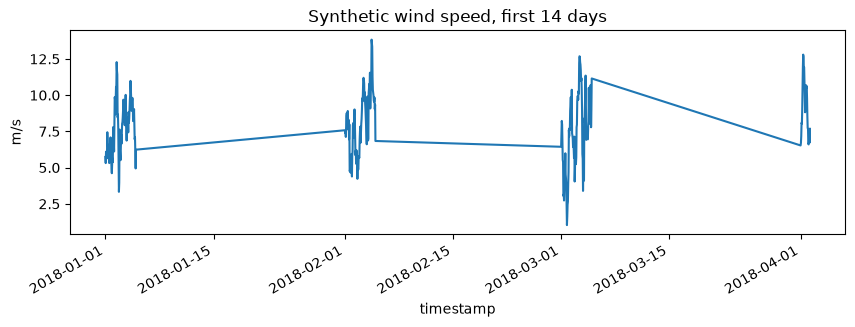

In [4]:
raw['wind_speed'].iloc[:24*14].plot(figsize=(10,3), title='Synthetic wind speed, first 14 days'); plt.ylabel('m/s'); plt.show()

## 2. Engineered features (cyclical time, turbulence intensity, 3-h rate of change)

In [5]:
df = add_features(raw); X, y = make_windows(df, lookback=24); wi = list(df.columns).index('wind_speed')
tr, va, te = chrono_split(len(X)); sc = Scaler().fit(X[tr]); Xs = sc.transform(X).astype('float32')
last = X[:, -1, wi]                     # last reading = persistence forecast
d = y - last                            # target: change from the last reading
ym, ys = d[tr].mean(), d[tr].std(); yn = ((d-ym)/ys).astype('float32')

/tmp/ipykernel_203871/799153467.py:55: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  h, doy = d.index.hour, d.index.dayofyear


## 3. Train a small CNN-LSTM briefly and evaluate

In [6]:
m = fit(CNNLSTM(X.shape[2]), Xs[tr], yn[tr], Xs[va], yn[va], epochs=EPOCHS, patience=6)
pred = last[te] + predict(m, Xs[te])*ys + ym   # add the predicted change back
print('CNN-LSTM   ', regression_metrics(y[te], pred))
print('persistence', regression_metrics(y[te], X[te][:, -1, wi]))

CNN-LSTM    {'MAE': 0.7315102219581604, 'RMSE': 1.0036738770752582, 'MAPE_%': 9.487822671464631, 'R2': 0.8215151640937124}
persistence {'MAE': 0.7786463048723009, 'RMSE': 1.0788346983033934, 'MAPE_%': 10.084407356304313, 'R2': 0.7937823207879058}


### Result in plain words
- **1 h ahead:** model RMSE 1.004 m/s vs persistence 1.079 m/s (R² 0.822 vs 0.794). The model beats persistence here.

These numbers come from about a minute of training on synthetic data. They show that the code works and learns something useful beyond "next hour = this hour"; they are not the paper's results.

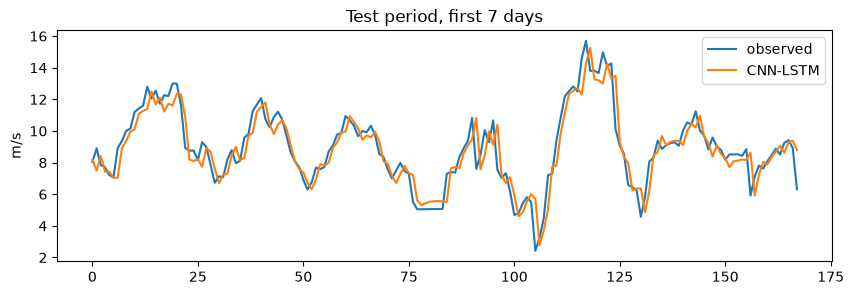

In [7]:
plt.figure(figsize=(10,3)); plt.plot(y[te][:168], label='observed'); plt.plot(pred[:168], label='CNN-LSTM'); plt.legend(); plt.ylabel('m/s'); plt.title('Test period, first 7 days'); plt.show()

## 4. Health index on a simulated degrading turbine (what the n8n `Anomaly Check` node acts on)

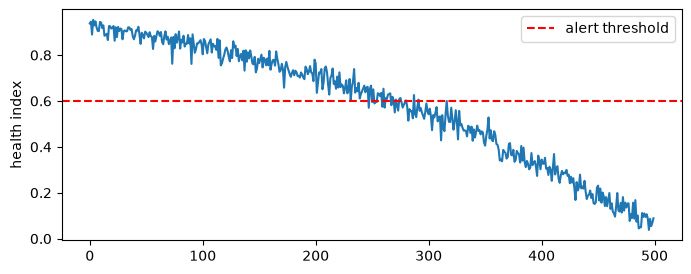

In [8]:
h = [health_index(s)['health_index'] for s in simulate_degradation()]
plt.figure(figsize=(8,3)); plt.plot(h); plt.axhline(ALERT, ls='--', c='r', label='alert threshold'); plt.legend(); plt.ylabel('health index'); plt.show()